## Data Preprocessing ##

In [1]:
import random
import pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import distance
import sklearn.metrics
import sklearn.datasets
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn import svm
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets

In [2]:
mean = (0.49139968, 0.48215827 ,0.44653124)
std = (0.24703233, 0.24348505, 0.26158768)

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.RandomHorizontalFlip(),
    # transforms.RandomRotation(10),
    transforms.Normalize(mean, std),
    # transforms.Grayscale(),
    torch.flatten
])

train_size = 50000
test_size = 10000
train_dataset =  datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset, shuffle=True, batch_size=train_size, num_workers=2)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, shuffle=True, batch_size=test_size, num_workers=2)

Files already downloaded and verified
Files already downloaded and verified


In [257]:
images_train, labels_train = next(iter(train_loader))
images_test, labels_test = next(iter(test_loader))

### Cifar10 Classes ###

In [5]:
classes = ('airplane', 
           'auto', 
           'bird',
           'cat',
           'deer',
           'dog', 
           'frog', 
           'horse', 
           'ship',
           'truck')

## My Support Vector Machine ##

### Hinge Loss function and it's Derivative

In [6]:
def Hinge(y_true, y_pred):
    return max(0, 1 - y_true * y_pred)

def Hingeprime(y_true, y_pred, C):
    n = y_true.size
    gradient = np.zeros(n)
    if (1 - y_true * y_pred) > 0:
        gradient = y_true * C
    return np.array(gradient)

### Dense Layer ###

In [7]:
class Layer():
    def __init__(self):
        self.input = None
        self.output = None
        self.grad = None
        
    def forward(self, input):
        # TODO: return output
        pass

    def backward(self, gradient):
        # TODO: update parameters and return input gradient
        pass

class Dense(Layer):
    def __init__(self, input_size, output_size):
        super().__init__()
        # self.weights = np.random.randn(output_size, input_size) * (np.sqrt(2 / input_size ))
        self.weights = np.zeros([output_size, input_size])
        self.bias = np.zeros([output_size,1])
        
    def forward(self, input):
        if input.ndim == 1:
            input = input[:,np.newaxis]
        self.input = input
        result = np.matmul(self.weights, self.input) - self.bias
        return result
    
    def backward(self, gradient):
        gradient = gradient * np.ones((1,1))
        weights_gradient = np.matmul(gradient, self.input.T)
        input_gradient = np.matmul(self.weights.T, gradient)
        if len(gradient) > 0:
            self.grad = np.concat((weights_gradient, gradient), axis = 1)
        return input_gradient

### Stochastic Gradient Descent Optimizer with Weight Decay ###

In [8]:
class SGD():
    def __init__(self, layers, lr = 0.001, weight_decay=0.01):
        self.lr = lr
        self.decay = weight_decay
        self.layers = layers

    def update(self, grads):
        for i, layer in enumerate(reversed(self.layers)):
            
            if type(layer) == Dense:
                size = layer.weights.shape[1]
                
                layer.weights -= self.lr * ((2 * self.decay * layer.weights) - grads[i][:,:size]) 
                layer.bias -= self.lr * grads[i][:,size:]
           

### Support Vector Machine ###

In [9]:
class MySVM():
    
    def __init__(self, layers):
        self.layers = layers

    def save_model(self, name, epoch):
        weights = []
        bias = []
        for layer in reversed(self.layers):
            if type(layer) == Dense:
                weights.append(layer.weights)
                bias.append(layer.bias)
            else:
                weights.append([])
                bias.append([])
        
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'ab')
        pickle.dump(weights, dbfile)                    
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'ab')
        pickle.dump(bias, dbfile)                    
        dbfile.close()

    def load_model(self, name, epoch):
        dbfile = open('models/'+name+ 'weights_e'+ epoch, 'rb')    
        weights = pickle.load(dbfile)
        dbfile.close()

        dbfile = open('models/'+name+ 'bias_e'+ epoch, 'rb')    
        bias = pickle.load(dbfile)
        dbfile.close()

        for i, layer in enumerate(reversed(self.layers)):
            if type(layer) == Dense:
                layer.weights = weights[i]
                layer.bias = bias[i]

    def train(self, name, X_train, y_train, X_test, y_test, max_iter=1000, learning_rate= 0.001, weight_decay = 0.01, C=1, verbose=True):
        optim = SGD(self.layers, learning_rate, weight_decay)

        train_acc = []
        val_acc = []
        n = X_train.shape[0]
        for e in range(max_iter):
            error = 0
            correct = 0
            best = 0
            for id in range(n):
                x = X_train[id]
                y = y_train[id]
                output = self._predict(x)
                preds = np.sign(output)
                error += Hinge(y, output[0][0]) #Hinge Loss
                new_grad = Hingeprime(y, output, C) #Derivative of Hinge Loss
                #Backpropagation
                grad = []
                for i, layer in enumerate(reversed(self.layers)):
                    grad.append([])
                    new_grad = layer.backward(new_grad)
                    grad[i] = np.array(layer.grad)
                optim.update(grad)
                correct += np.sign(preds)[0][0] == y
            accuracy = float(correct) / n

            if accuracy > best:
                best = accuracy
                self.save_model(name, "best")
            
            error /= n
            if verbose:
                predictions = []
                for x in X_test:
                    predictions.append(self.predict(x)[0][0])
                val = float(np.sum(predictions == y_test)) / len(y_test)
                val_acc.append(val)
                train_acc.append(accuracy)

                print(f"{e + 1}/{max_iter}, error={error}, train accuracy={accuracy}, validation accuracy={val}")
        if verbose:
            plt.plot(np.arange(max_iter), train_acc, label='Training Accuracy')
            plt.plot(np.arange(max_iter), val_acc, label='Validation Accuracy')
            plt.legend()
            plt.show()
            # print(self.layers[0].weights)
            # print(self.layers[0].bias)

    def _predict(self, X):
        if X.ndim == 1:
            output = X
            for layer in self.layers:
                output = layer.forward(output)
            return np.array(output)
        output = [0 for _ in X]
        for i, x in enumerate(X):
            output[i] = x
            for layer in self.layers:
                output[i] = layer.forward(output[i])
            output[i] = output[i].squeeze()
        return np.array(output)
    def predict(self, input):
        # print(input)
        return np.sign(self._predict(input))

# Two classes training examples, Visualization and Comparison with sklearn Support Vector Classifiers #

### Visualization function ###

In [10]:
def visualization(X, Xtest, y, ytest, w, b):
    def get_line(x, w, b):
        return (-w[0] * x + b) / w[1]

    xmin = np.amin(X[:, 0])
    xmax = np.amax(X[:, 0])
    ymin = np.amin(X[:, 1])
    ymax = np.amax(X[:, 1])
    
    line0 = get_line(xmin, w, b)
    line1 = get_line(xmax, w, b)
    margin0plus = get_line(xmin, w, b-1)
    margin1plus = get_line(xmax, w, b-1)
    margin0minus = get_line(xmin, w, b+1)
    margin1minus = get_line(xmax, w, b+1)

    fig = plt.figure()
    ax = fig.add_subplot(1, 1, 1)
    plt.scatter(X[:, 0], X[:, 1], marker="o", c=y, cmap='plasma')
    plt.scatter(Xtest[:, 0], Xtest[:, 1], marker="o", c=ytest)
    ax.plot([xmin, xmax], [line0, line1], "r", label=str(round(w[1],4)) + 'y='+ str(round(w[0],4)) + 'x +' +str(round(b[0],4)))
    ax.plot([xmin, xmax], [margin0plus, margin1plus], "k--")
    ax.plot([xmin, xmax], [margin0minus, margin1minus], "k--")
    ax.set_ylim([ymin - 3, ymax + 3])
    ax.set_label('')
    plt.legend()
    plt.show()

## Building a two dimensional data example ##

In [11]:
# train_state = np.random.randint(0,1000)
# test_state = np.random.randint(0,1000)
train_state = 341
test_state = 68
print("Train random state", train_state)
print("Test random state", test_state)

Train random state 341
Test random state 68


In [12]:
X, y = sklearn.datasets.make_blobs(n_samples=200, n_features=2, centers=2, cluster_std=1.05, random_state=train_state)
y = np.where(y == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=test_state)

### My SVM ###

1/200, error=0.24175054472885113, train accuracy=0.9583333333333334, validation accuracy=1.0
2/200, error=0.01126607375889942, train accuracy=1.0, validation accuracy=1.0
3/200, error=0.004474677512101114, train accuracy=1.0, validation accuracy=1.0
4/200, error=0.0031722030172348426, train accuracy=1.0, validation accuracy=1.0
5/200, error=0.0022829596629317345, train accuracy=1.0, validation accuracy=1.0
6/200, error=0.0014471777069616702, train accuracy=1.0, validation accuracy=1.0
7/200, error=0.0006025222727613781, train accuracy=1.0, validation accuracy=1.0
8/200, error=0.0007359536412862373, train accuracy=1.0, validation accuracy=1.0
9/200, error=0.0008810502925250457, train accuracy=1.0, validation accuracy=1.0
10/200, error=0.0007007425266441279, train accuracy=1.0, validation accuracy=1.0
11/200, error=0.0005208669848471976, train accuracy=1.0, validation accuracy=1.0
12/200, error=0.0, train accuracy=1.0, validation accuracy=1.0
13/200, error=0.0004159021851903283, train ac

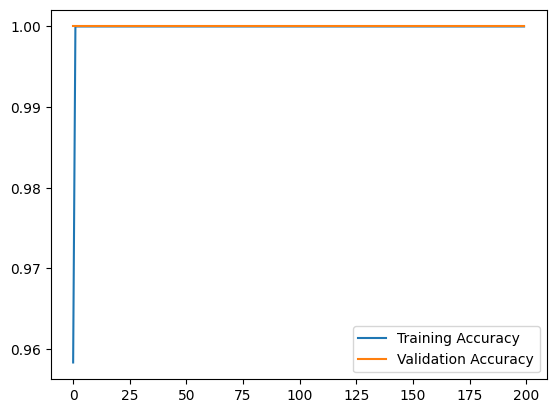

In [13]:
layers = [ 
    Dense(X_train.shape[1], 1)
]

svc = MySVM(layers)
max_iter = 200
svc.train('MySVM', X_train, y_train, X_test, y_test, max_iter = max_iter, learning_rate = 0.001, C = 1, verbose=True)

### Results ###

              precision    recall  f1-score   support

          -1       1.00      1.00      1.00        36
           1       1.00      1.00      1.00        44

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



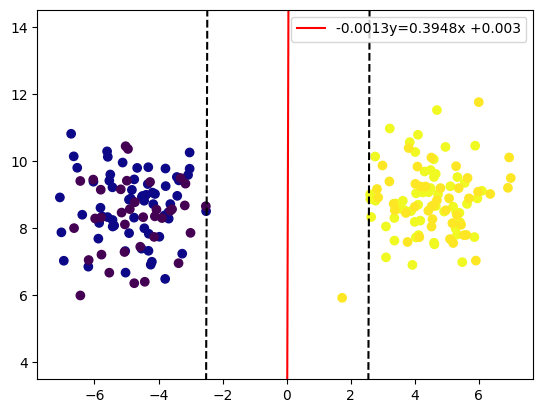

In [14]:
predictions_MySVC = svc.predict(X_test)

print(sklearn.metrics.classification_report(y_test, predictions_MySVC))

visualization(X_train, X_test, y_train, y_test, svc.layers[0].weights[0], svc.layers[0].bias[0])

### sklearn SVM ###

In [15]:
sklearnSVC = svm.LinearSVC(C=1, penalty='l2', loss='hinge')
sklearnSVC.fit(X_train, y_train)

c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC(C=1, loss='hinge')

### Results ###

              precision    recall  f1-score   support

          -1       1.00      1.00      1.00        36
           1       1.00      1.00      1.00        44

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



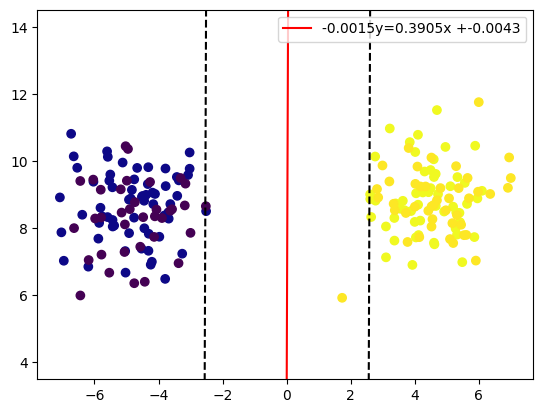

In [16]:
predictions_SVC = sklearnSVC.predict(X_test)
print(sklearn.metrics.classification_report(y_test, predictions_SVC))
visualization(X_train, X_test, y_train, y_test, sklearnSVC.coef_[0], sklearnSVC.intercept_)

## Non-linearly separable two dimensional example ##

In [17]:
# train_state = np.random.randint(0,1000)
# test_state = np.random.randint(0,1000)
train_state = 925
test_state = 213
print("Train random state", train_state)
print("Test random state", test_state)

Train random state 925
Test random state 213


In [18]:
X, y = sklearn.datasets.make_blobs(n_samples=200, n_features=2, centers=2, cluster_std=1.5, random_state=train_state)
y = np.where(y == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=test_state)

### C = 1 ###

1/200, error=0.8257702218806905, train accuracy=0.5666666666666667, validation accuracy=0.475
2/200, error=0.775592917840625, train accuracy=0.5166666666666667, validation accuracy=0.475
3/200, error=0.7710852482593229, train accuracy=0.5166666666666667, validation accuracy=0.4875
4/200, error=0.7633723899301958, train accuracy=0.5166666666666667, validation accuracy=0.4875
5/200, error=0.7535460110524597, train accuracy=0.525, validation accuracy=0.4875
6/200, error=0.7515369222146366, train accuracy=0.5583333333333333, validation accuracy=0.5
7/200, error=0.7443896949009285, train accuracy=0.6, validation accuracy=0.5
8/200, error=0.7389407471645186, train accuracy=0.6, validation accuracy=0.5125
9/200, error=0.7354072071994564, train accuracy=0.6083333333333333, validation accuracy=0.5125
10/200, error=0.7296867833717092, train accuracy=0.6166666666666667, validation accuracy=0.5125
11/200, error=0.7239685659344838, train accuracy=0.6166666666666667, validation accuracy=0.525
12/200

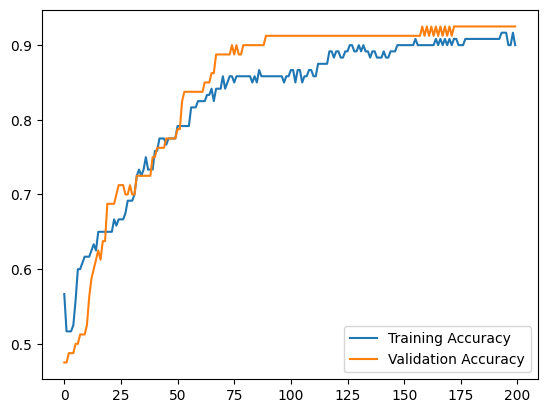

In [19]:
layers = [ 
    Dense(X_train.shape[1], 1)
]

svc = MySVM(layers)
max_iter = 200
svc.train('MySVM', X_train, y_train, X_test, y_test, max_iter = max_iter, learning_rate = 0.001, C = 1, verbose=True)

### Results ###

              precision    recall  f1-score   support

          -1       0.95      0.90      0.93        42
           1       0.90      0.95      0.92        38

    accuracy                           0.93        80
   macro avg       0.93      0.93      0.92        80
weighted avg       0.93      0.93      0.93        80



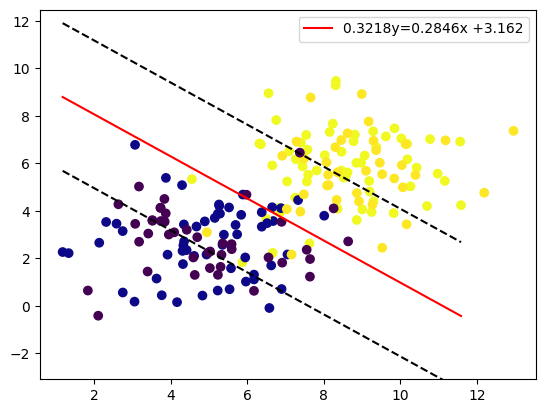

In [20]:
predictions_MySVC = svc.predict(X_test)

print(sklearn.metrics.classification_report(y_test, predictions_MySVC))

visualization(X_train, X_test, y_train, y_test, svc.layers[0].weights[0], svc.layers[0].bias[0])

### C = 10 ###

1/200, error=0.9283761849820142, train accuracy=0.5583333333333333, validation accuracy=0.6
2/200, error=0.8200426243400839, train accuracy=0.625, validation accuracy=0.6
3/200, error=0.7613783880320633, train accuracy=0.6583333333333333, validation accuracy=0.6875
4/200, error=0.7253163484947414, train accuracy=0.675, validation accuracy=0.7125
5/200, error=0.6784299781174841, train accuracy=0.675, validation accuracy=0.725
6/200, error=0.656721647797671, train accuracy=0.7, validation accuracy=0.7125
7/200, error=0.6105016944174465, train accuracy=0.7333333333333333, validation accuracy=0.75
8/200, error=0.5714065383696582, train accuracy=0.75, validation accuracy=0.9
9/200, error=0.5463438456847423, train accuracy=0.75, validation accuracy=0.8
10/200, error=0.5054001324655425, train accuracy=0.7833333333333333, validation accuracy=0.8625
11/200, error=0.4761532579584633, train accuracy=0.7916666666666666, validation accuracy=0.9125
12/200, error=0.4656642348873246, train accuracy=0.

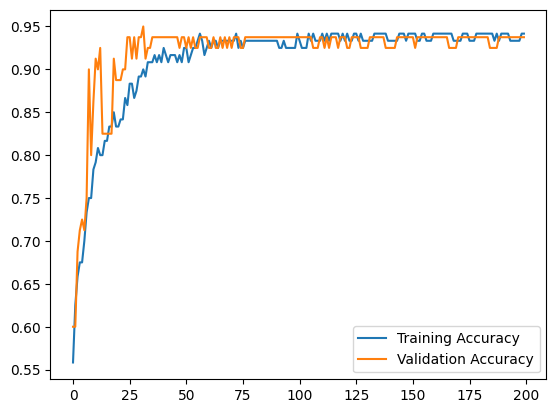

In [21]:
layers = [ 
    Dense(X_train.shape[1], 1)
]

svc = MySVM(layers)
max_iter = 200
svc.train('MySVM', X_train, y_train, X_test, y_test, max_iter = max_iter, learning_rate = 0.001, C = 10, verbose=True)

### Results ###

              precision    recall  f1-score   support

          -1       0.95      0.93      0.94        42
           1       0.92      0.95      0.94        38

    accuracy                           0.94        80
   macro avg       0.94      0.94      0.94        80
weighted avg       0.94      0.94      0.94        80



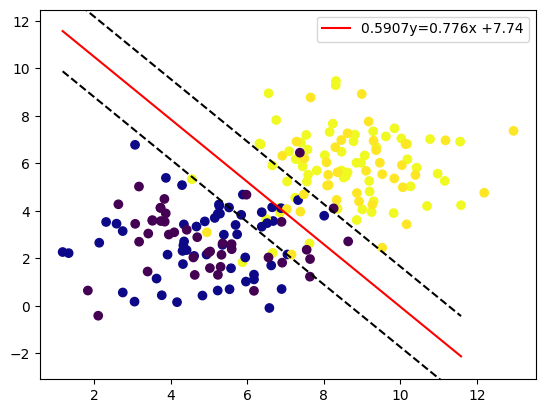

In [22]:
predictions_MySVC = svc.predict(X_test)

print(sklearn.metrics.classification_report(y_test, predictions_MySVC))

visualization(X_train, X_test, y_train, y_test, svc.layers[0].weights[0], svc.layers[0].bias[0])

## Classifier of two Cifar10 classes ##

### Selecting only two classes from the Cifar10 Dataset ###

In [23]:
class0 = 0
class1 = 1
mask_train = (labels_train == class0) | (labels_train == class1)
mask_test = (labels_test == class0) | (labels_test == class1)
images_train_masked = images_train[mask_train]
labels_train_masked = labels_train[mask_train]
images_test_masked = images_test[mask_test]
labels_test_masked = labels_test[mask_test]
labels_train_masked = np.where(labels_train_masked == class0, 1, -1)
labels_test_masked = np.where(labels_test_masked == class0, 1, -1)

### My SVM ###

C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_19896\510772374.py:26: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) - self.bias
C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_19896\510772374.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  weights_gradient = np.matmul(gradient, self.input.T)


1/100, error=0.8127035159387587, train accuracy=0.7646, validation accuracy=0.776
2/100, error=0.7549724842606977, train accuracy=0.7823, validation accuracy=0.79
3/100, error=0.7500150460625873, train accuracy=0.7882, validation accuracy=0.7895
4/100, error=0.7305635167347239, train accuracy=0.7908, validation accuracy=0.7985
5/100, error=0.7340107750998511, train accuracy=0.7889, validation accuracy=0.7965
6/100, error=0.7275230528223591, train accuracy=0.7905, validation accuracy=0.8015
7/100, error=0.7166247922089145, train accuracy=0.7952, validation accuracy=0.7895
8/100, error=0.716228201648059, train accuracy=0.7929, validation accuracy=0.7885
9/100, error=0.7154820159131591, train accuracy=0.7954, validation accuracy=0.7815
10/100, error=0.7103903069145415, train accuracy=0.796, validation accuracy=0.796
11/100, error=0.715572629627376, train accuracy=0.7937, validation accuracy=0.8055
12/100, error=0.7138388916002995, train accuracy=0.7964, validation accuracy=0.779
13/100, e

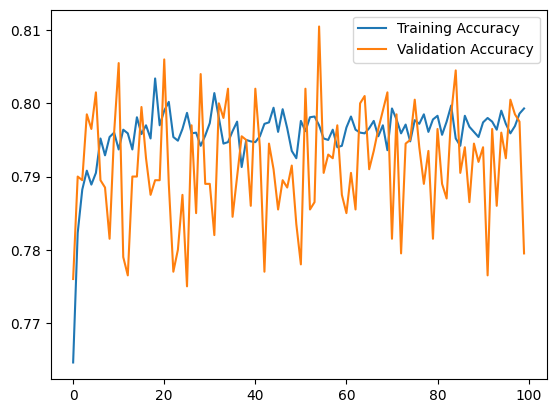

In [61]:
layers = [ 
    Dense(images_train_masked.shape[1], 1)
]

svc = MySVM(layers)
max_iter = 100
svc.train('MySVM', images_train_masked, labels_train_masked, images_test_masked, labels_test_masked, max_iter = max_iter, learning_rate = 0.001, C = 1, verbose=True)

In [62]:
predictions_MySVC = svc.predict(images_test_masked)
print(sklearn.metrics.classification_report(labels_test_masked, predictions_MySVC))

              precision    recall  f1-score   support

          -1       0.80      0.74      0.77      1000
           1       0.76      0.82      0.79      1000

    accuracy                           0.78      2000
   macro avg       0.78      0.78      0.78      2000
weighted avg       0.78      0.78      0.78      2000



C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_19896\510772374.py:26: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  result = np.matmul(self.weights, self.input) - self.bias


### sklearn SVM ###

In [63]:
sklearnSVC = svm.LinearSVC(C=1, penalty='l2', loss='hinge', max_iter=100)
sklearnSVC.fit(images_train_masked, labels_train_masked)

c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\svm\_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC(C=1, loss='hinge', max_iter=100)

In [ ]:
predictions_SVC = sklearnSVC.predict(images_test_masked)
print(sklearn.metrics.classification_report(labels_test_masked, predictions_SVC))

              precision    recall  f1-score   support

          -1       0.80      0.69      0.74      1000
           1       0.73      0.83      0.78      1000

    accuracy                           0.76      2000
   macro avg       0.77      0.76      0.76      2000
weighted avg       0.77      0.76      0.76      2000



# Classification using the Cifar10 Dataset #

## Different Classifiers ##

### Sklearn k-Nearest Neighbors for k = 1 ###

In [28]:
classifier_1NC = KNeighborsClassifier(n_neighbors=1)

classifier_1NC.fit(images_train, labels_train)
predictions_1NC = classifier_1NC.predict(images_test)

c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Tzagkari\AppData\Local\Programs\Python\Python3

              precision    recall  f1-score   support

           0       0.43      0.48      0.45      1000
           1       0.65      0.22      0.33      1000
           2       0.24      0.39      0.30      1000
           3       0.30      0.24      0.27      1000
           4       0.25      0.46      0.32      1000
           5       0.36      0.29      0.32      1000
           6       0.33      0.35      0.34      1000
           7       0.56      0.30      0.39      1000
           8       0.40      0.62      0.48      1000
           9       0.59      0.19      0.29      1000

    accuracy                           0.35     10000
   macro avg       0.41      0.35      0.35     10000
weighted avg       0.41      0.35      0.35     10000



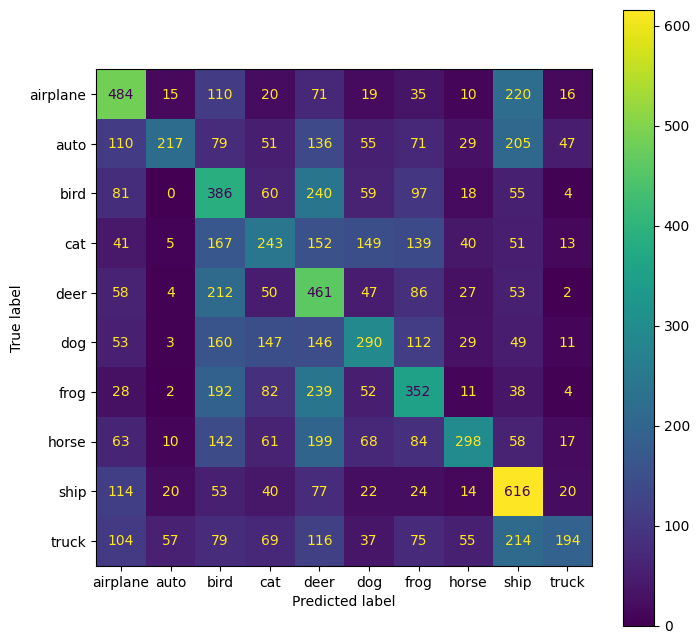

In [29]:
print(sklearn.metrics.classification_report(labels_test, predictions_1NC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_1NC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Sklearn k-Nearest Neighbors for k = 3 ###

In [73]:
classifier_3NC = KNeighborsClassifier(n_neighbors=3)

classifier_3NC.fit(images_train, labels_train)
distances_3NC, indices_3NC = classifier_3NC.kneighbors(images_test, n_neighbors=3, return_distance=True)
kneighbors_3NC = [labels_train[i] for i in indices_3NC]
predictions_3NC = [int(Counter(i.numpy()).most_common(3)[0][0]) for i in kneighbors_3NC]

              precision    recall  f1-score   support

           0       0.43      0.48      0.45      1000
           1       0.68      0.21      0.32      1000
           2       0.25      0.39      0.31      1000
           3       0.29      0.22      0.25      1000
           4       0.25      0.49      0.33      1000
           5       0.39      0.29      0.33      1000
           6       0.32      0.34      0.33      1000
           7       0.57      0.28      0.37      1000
           8       0.39      0.65      0.49      1000
           9       0.61      0.19      0.29      1000

    accuracy                           0.35     10000
   macro avg       0.42      0.35      0.35     10000
weighted avg       0.42      0.35      0.35     10000



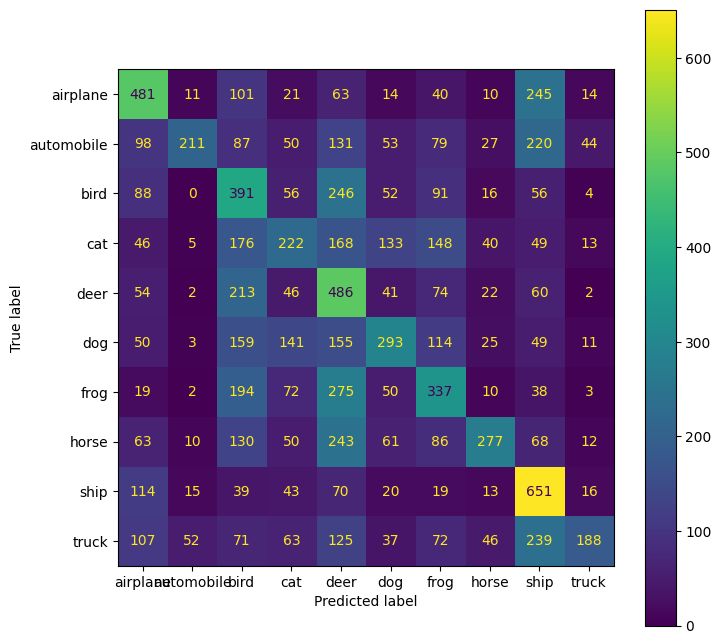

In [74]:
print(sklearn.metrics.classification_report(labels_test, predictions_3NC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_3NC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Sklearn Nearest Centroid ###

In [34]:
classifier_NC = NearestCentroid()

classifier_NC.fit(images_train, labels_train)
predictions_NC = classifier_NC.predict(images_test)

              precision    recall  f1-score   support

           0       0.27      0.53      0.35      1000
           1       0.27      0.18      0.22      1000
           2       0.29      0.11      0.16      1000
           3       0.27      0.06      0.09      1000
           4       0.28      0.12      0.17      1000
           5       0.27      0.29      0.28      1000
           6       0.22      0.53      0.31      1000
           7       0.26      0.17      0.20      1000
           8       0.42      0.37      0.39      1000
           9       0.33      0.41      0.36      1000

    accuracy                           0.28     10000
   macro avg       0.29      0.28      0.25     10000
weighted avg       0.29      0.28      0.25     10000



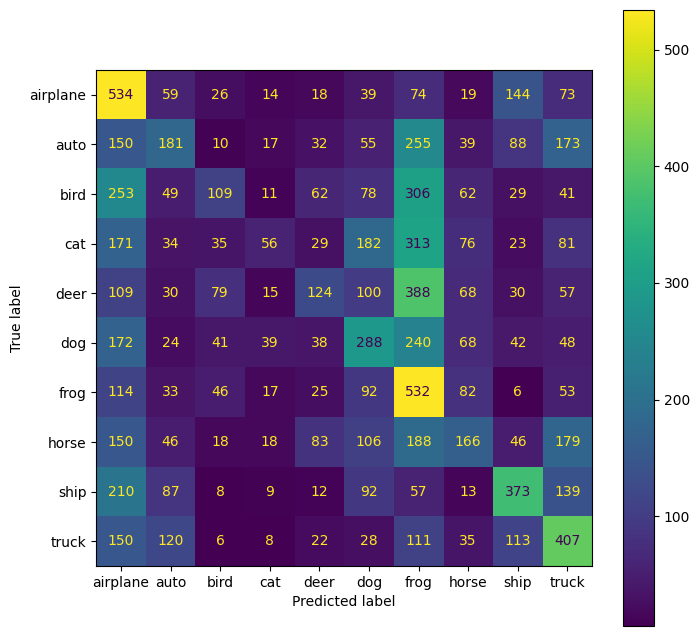

In [35]:
print(sklearn.metrics.classification_report(labels_test, predictions_NC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_NC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Train function for Pytorch models ###

In [37]:
def train(model, name, criterion, optimizer, train_loader, images_test, labels, epochs = 20):
    loss_values = []
    train_acc = []
    val_acc = []
    best = 0

    for e in range(epochs):
        correct = 0
        for id_batch, (x_batch, y_batch) in enumerate(train_loader):
            y = y_batch.numpy()
            y_train = np.zeros([y.size, 10])
            y_train[np.arange(y.size), y] = 1
            y_train = torch.Tensor(y_train)

            output = model(x_batch)
            predictions = [int(np.argmax(x)) for x in output.detach().numpy()]
            correct += np.sum(predictions == y)

            # Compute the loss (reconstruction error)
            loss = criterion(output, y_batch)
            # Backpropagation and optimization
            optimizer.zero_grad()  # Clear previous gradients
            loss.backward()        # Backpropagate the error
            optimizer.step()       # Update the weights
        accuracy = float(correct) / len(train_loader.dataset)
        if accuracy > best:
            torch.save(model, 'models/'+ name +'.pth')

        predictions = [int(np.argmax(x)) for x in model(torch.Tensor(images_test)).detach().numpy()]
        val = float(np.sum(predictions == labels.numpy())) / len(labels)
        print(f"{e + 1}/{epochs}, error={loss.item():.4f}, train accuracy={accuracy}, validation accuracy={val}")
        loss_values.append(loss.item())
        train_acc.append(accuracy)
        val_acc.append(val)
    plt.plot(np.arange(epochs), train_acc, label='Training Accuracy')
    plt.plot(np.arange(epochs), val_acc, label='Validation Accuracy')
    plt.legend()
    plt.show()
    plt.close()


### One Hidden Layer MLP with Hinge Loss ###

In [38]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super(MLP, self).__init__()

        self.model = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.ReLU(),
            # nn.Dropout(0.1),
            nn.Linear(256, 10))
    def forward(self, x):
        return self.model.forward(x)

mlp = MLP(train_dataset[0][0].numpy().size)
criterion = nn.MultiMarginLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr = 0.01, weight_decay=1e-5) 

# epochs = 100
# train(mlp, 'torch2', criterion, optimizer, train_loader, images_test, labels_test, epochs)
# mlp = torch.load('models/torch2.pth')

              precision    recall  f1-score   support

           0       0.51      0.67      0.58      1000
           1       0.55      0.64      0.59      1000
           2       0.43      0.35      0.39      1000
           3       0.38      0.25      0.30      1000
           4       0.47      0.33      0.39      1000
           5       0.35      0.55      0.43      1000
           6       0.52      0.59      0.55      1000
           7       0.57      0.51      0.54      1000
           8       0.71      0.52      0.60      1000
           9       0.52      0.55      0.54      1000

    accuracy                           0.49     10000
   macro avg       0.50      0.49      0.49     10000
weighted avg       0.50      0.49      0.49     10000



C:\Users\Tzagkari\AppData\Local\Temp\ipykernel_19896\3785481733.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  mlp = torch.load('models/torch2.pth')


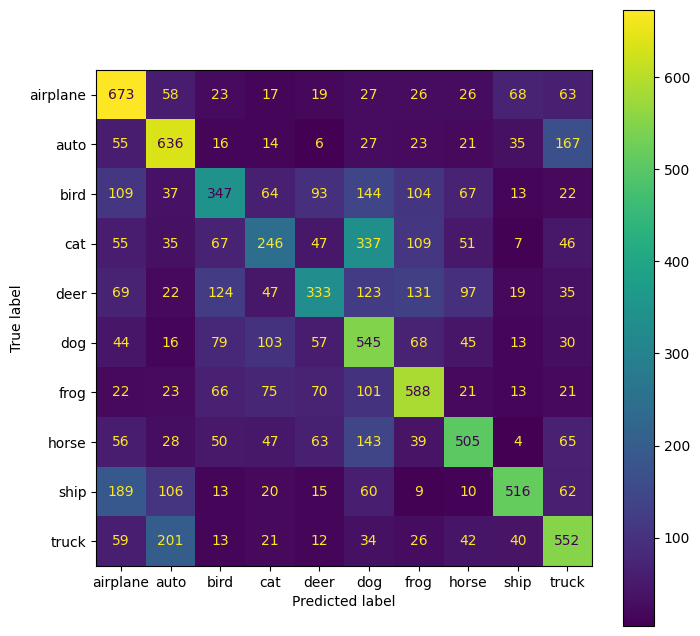

In [39]:
mlp = torch.load('models/torch2.pth')
predictions = [int(np.argmax(x)) for x in mlp(torch.Tensor(images_test)).detach().numpy()]
val = float(np.sum(predictions == labels_test.numpy())) / len(labels_test)
print(sklearn.metrics.classification_report(labels_test, predictions))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

## Support Vector Classifiers ##

### Linear Kernel ###

In [ ]:
# linear = svm.LinearSVC()

# linear.fit(images_train, labels_train)

# pickle.dump(linear, open('models/linear', 'wb'))

              precision    recall  f1-score   support

           0       0.43      0.51      0.47      1000
           1       0.45      0.48      0.47      1000
           2       0.30      0.31      0.30      1000
           3       0.27      0.28      0.27      1000
           4       0.34      0.29      0.32      1000
           5       0.32      0.31      0.31      1000
           6       0.44      0.47      0.45      1000
           7       0.48      0.41      0.45      1000
           8       0.53      0.53      0.53      1000
           9       0.47      0.45      0.46      1000

    accuracy                           0.40     10000
   macro avg       0.40      0.40      0.40     10000
weighted avg       0.40      0.40      0.40     10000



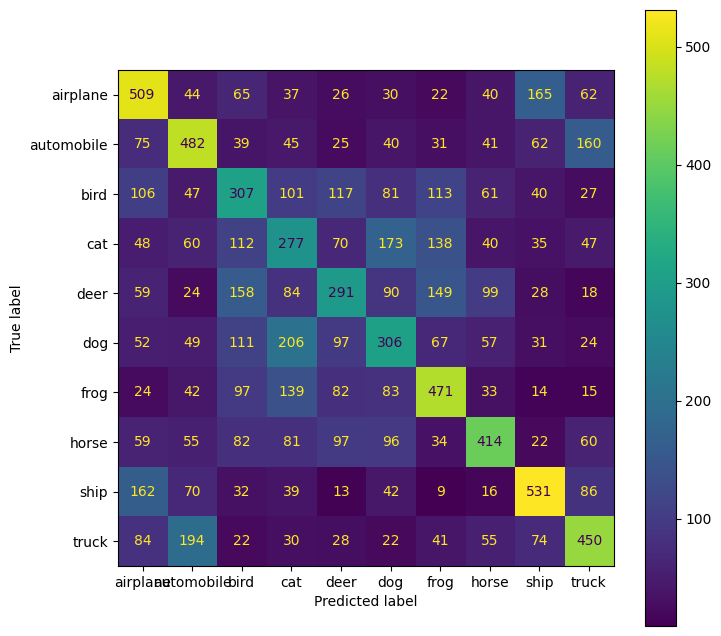

In [80]:
linear = pickle.load(open('models/bestlinear', 'rb'))
predictions_linear = linear.predict(images_test)
print(sklearn.metrics.classification_report(labels_test, predictions_linear))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_linear)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Polynomial Kernel ###

In [42]:
# poly = svm.SVC(kernel = 'poly', random_state=0)

# poly.fit(images_train, labels_train)

# pickle.dump(poly, open('models/poly', 'wb'))

              precision    recall  f1-score   support

           0       0.58      0.51      0.54      1000
           1       0.64      0.55      0.59      1000
           2       0.23      0.57      0.33      1000
           3       0.35      0.30      0.32      1000
           4       0.36      0.37      0.36      1000
           5       0.43      0.34      0.38      1000
           6       0.51      0.44      0.47      1000
           7       0.64      0.38      0.48      1000
           8       0.65      0.60      0.62      1000
           9       0.66      0.51      0.57      1000

    accuracy                           0.46     10000
   macro avg       0.50      0.46      0.47     10000
weighted avg       0.50      0.46      0.47     10000



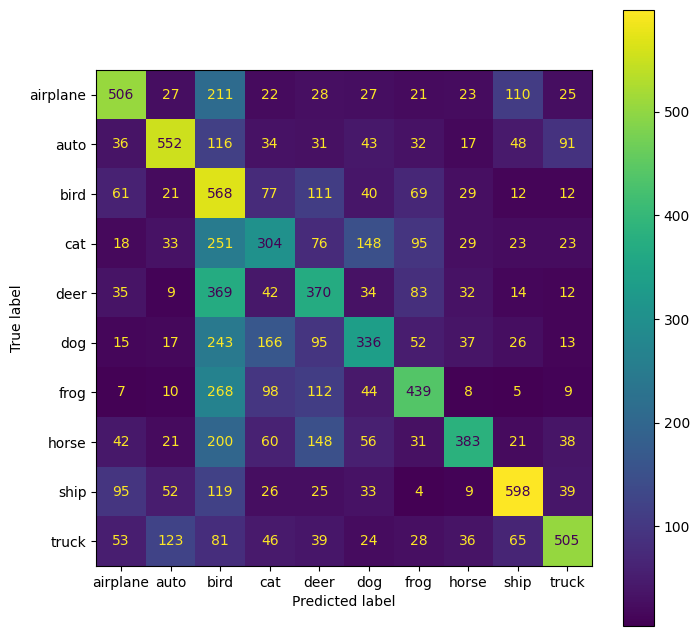

In [43]:
poly = pickle.load(open('models/poly', 'rb'))
predictions_poly = poly.predict(images_test)
print(sklearn.metrics.classification_report(labels_test, predictions_poly))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_poly)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Radial Basis Kernel ###

In [44]:
# SVC = svm.SVC(C= 1, kernel='rbf')

# SVC.fit(images_train, labels_train)

# pickle.dump(SVC, open('models/SVC', 'wb'))

              precision    recall  f1-score   support

           0       0.61      0.62      0.62      1000
           1       0.64      0.65      0.64      1000
           2       0.42      0.41      0.41      1000
           3       0.38      0.39      0.38      1000
           4       0.47      0.43      0.45      1000
           5       0.49      0.43      0.46      1000
           6       0.54      0.64      0.58      1000
           7       0.63      0.56      0.60      1000
           8       0.65      0.69      0.67      1000
           9       0.58      0.61      0.60      1000

    accuracy                           0.54     10000
   macro avg       0.54      0.54      0.54     10000
weighted avg       0.54      0.54      0.54     10000



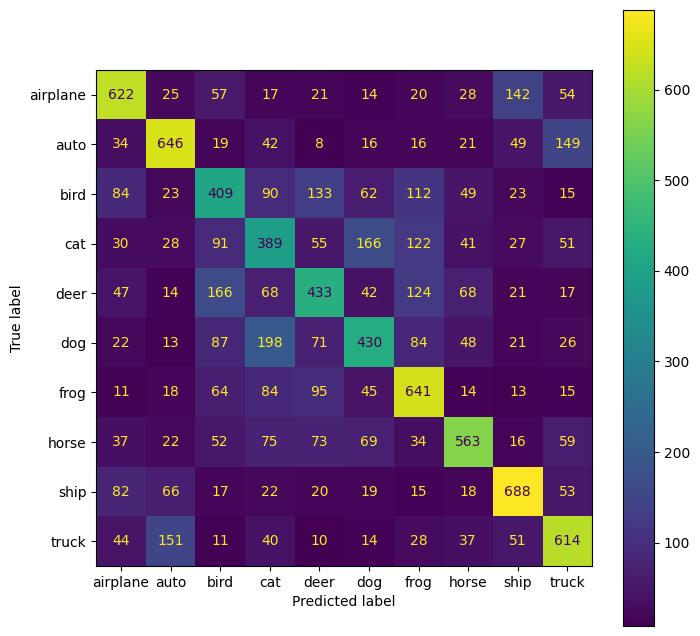

In [45]:
SVC = pickle.load(open('models/SVC', 'rb'))
predictions_SVC = SVC.predict(images_test)
print(sklearn.metrics.classification_report(labels_test, predictions_SVC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_SVC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Radial Basis Kernel C = 10, gamma=0.01 ###

In [46]:
# RBF = svm.SVC(C=10, gamma=0.01, kernel = 'rbf', random_state=0)

# RBF.fit(images_train, labels_train)

# pickle.dump(RBF, open('models/RBF', 'wb'))

              precision    recall  f1-score   support

           0       0.73      0.13      0.22      1000
           1       0.97      0.04      0.07      1000
           2       0.52      0.12      0.19      1000
           3       0.27      0.05      0.08      1000
           4       0.60      0.15      0.24      1000
           5       0.20      0.09      0.13      1000
           6       0.61      0.11      0.19      1000
           7       0.12      0.96      0.21      1000
           8       0.70      0.11      0.19      1000
           9       0.39      0.04      0.07      1000

    accuracy                           0.18     10000
   macro avg       0.51      0.18      0.16     10000
weighted avg       0.51      0.18      0.16     10000



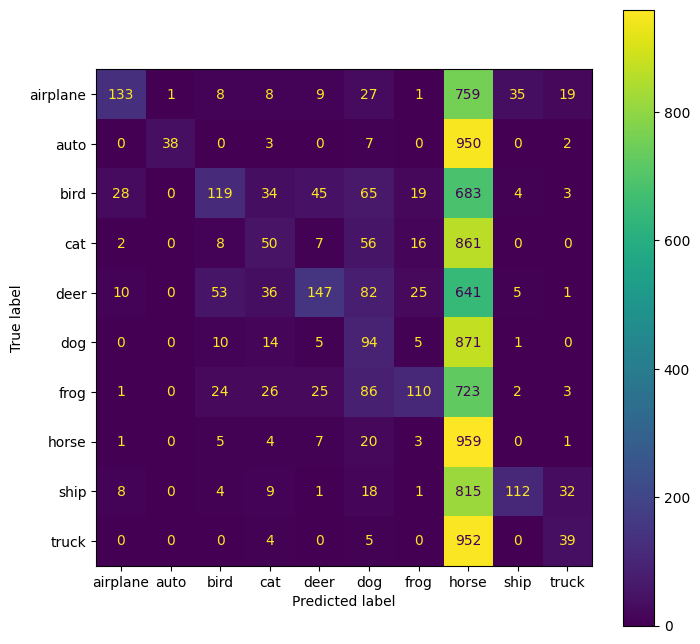

In [47]:
RBF = pickle.load(open('models/RBF', 'rb'))
predictions_RBF = RBF.predict(images_test)
print(sklearn.metrics.classification_report(labels_test, predictions_RBF))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_RBF)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

### Radial Basis Kernel C = 10, gamma=0.0001 ###

In [48]:
# bestSVC = svm.SVC(C= 10, gamma=0.0001, kernel='rbf')

# bestSVC.fit(images_train, labels_train)

# pickle.dump(bestSVC, open('models/bestSVC', 'wb'))

              precision    recall  f1-score   support

           0       0.60      0.63      0.62      1000
           1       0.65      0.65      0.65      1000
           2       0.43      0.44      0.43      1000
           3       0.39      0.40      0.40      1000
           4       0.47      0.46      0.47      1000
           5       0.49      0.43      0.46      1000
           6       0.55      0.62      0.59      1000
           7       0.65      0.57      0.60      1000
           8       0.67      0.70      0.68      1000
           9       0.61      0.59      0.60      1000

    accuracy                           0.55     10000
   macro avg       0.55      0.55      0.55     10000
weighted avg       0.55      0.55      0.55     10000



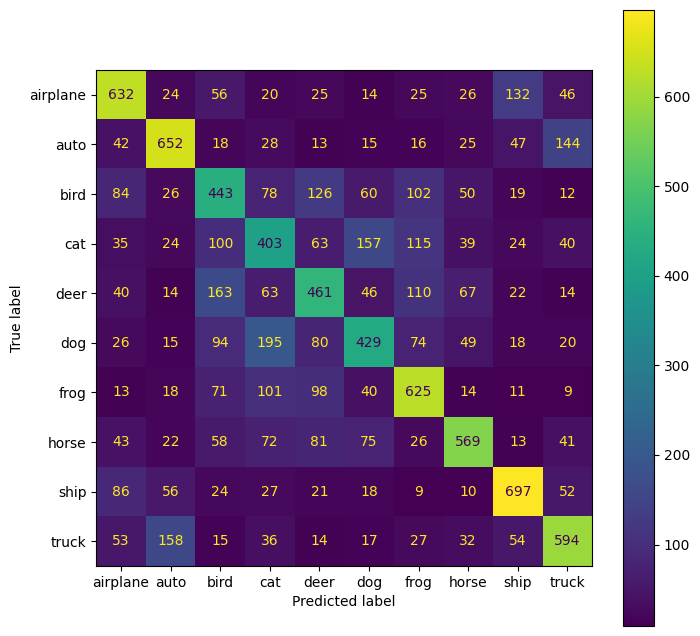

In [ ]:
bestSVC = pickle.load(open('models/bestSVC', 'rb'))
predictions_SVC = bestSVC.predict(images_test)
print(sklearn.metrics.classification_report(labels_test, predictions_SVC))

fig, ax = plt.subplots(figsize=(8,8))
confusion_matrix = sklearn.metrics.confusion_matrix(labels_test, predictions_SVC)
cm_display = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=classes)
cm_display.plot(ax=ax)
plt.show()

## Examples ##

### Support Vector examples ###

In [238]:
idx = []
sum = 0
for n in SVC.n_support_[:-1]:
    sum += n
    idx.append(sum)
supports = np.split(SVC.support_, idx)

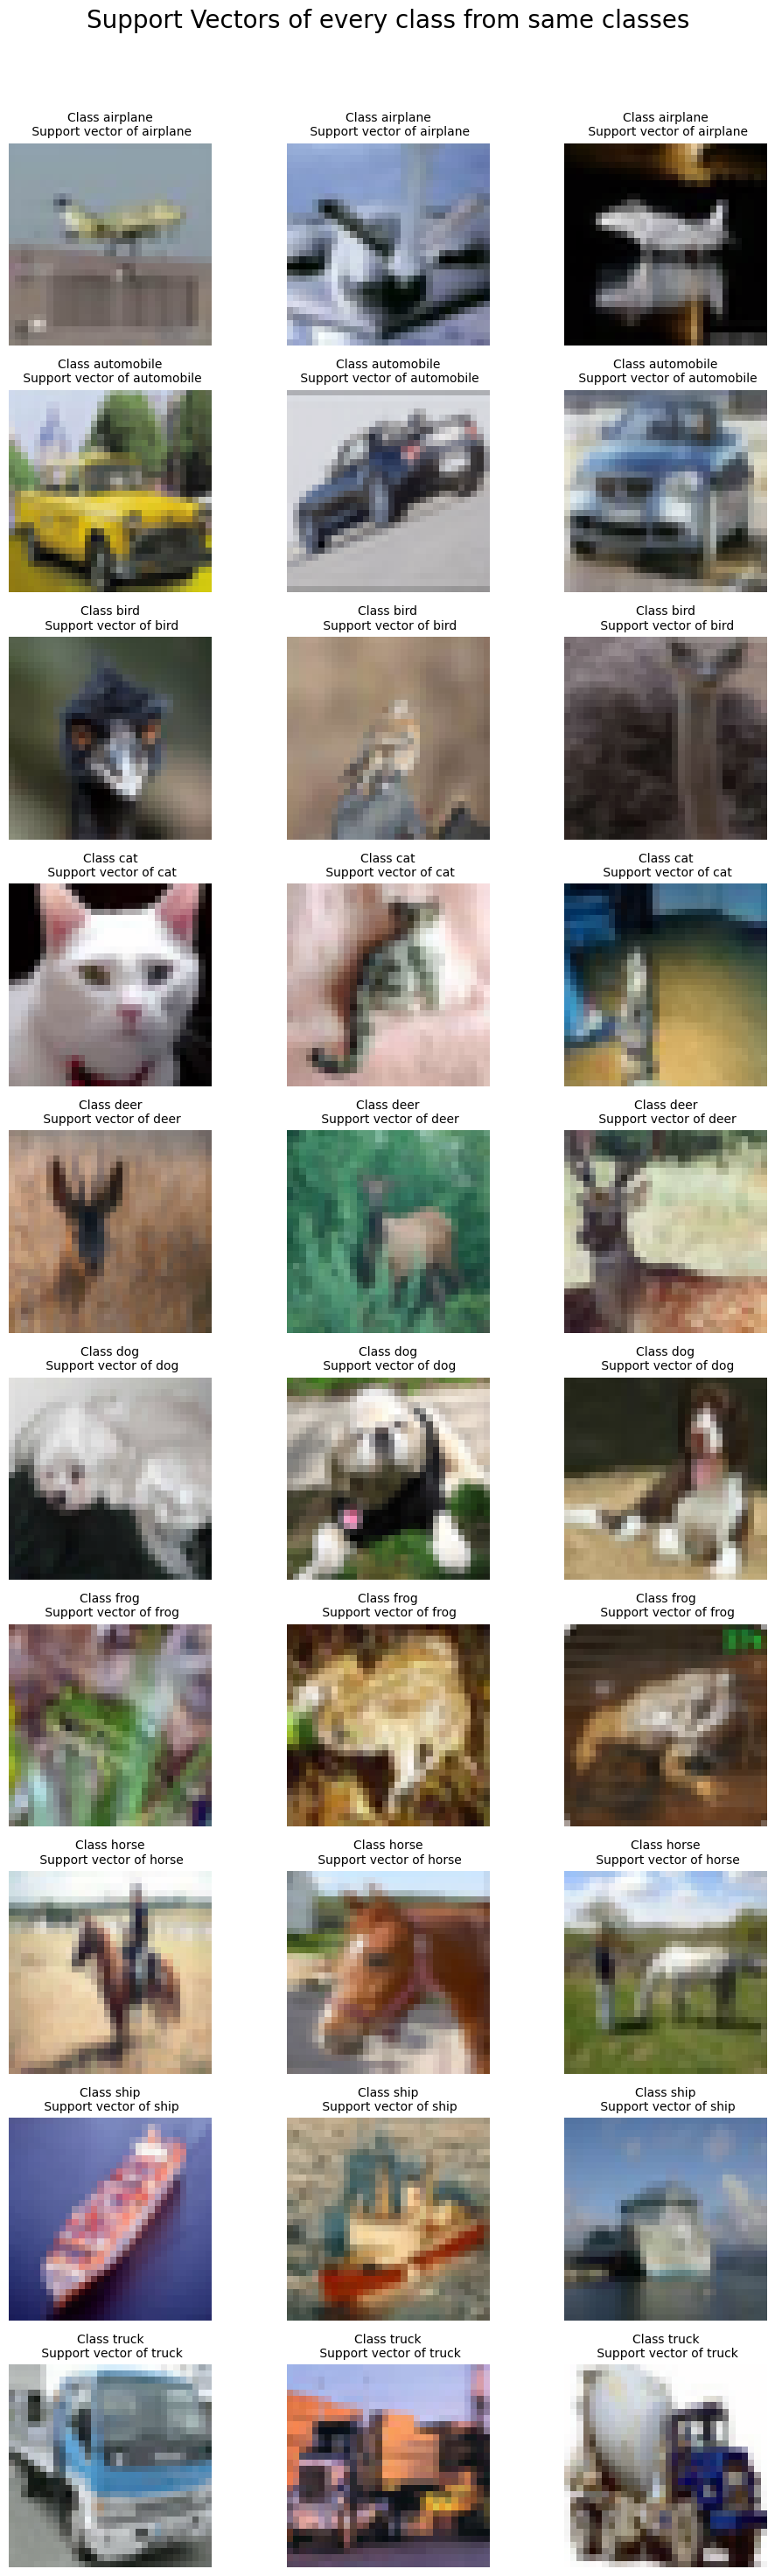

In [282]:
fig, axes = plt.subplots(10, 3, figsize=(10, 30))
fig.suptitle("Support Vectors of every class from same classes", fontsize=20)


for class_label in range(len(classes)):
    # Get support vectors corresponding to the current class
    class_support_vectors = images_train[supports[class_label]]
    label = labels_train[supports[class_label]]

    temp = list(zip(class_support_vectors, label))
    np.random.shuffle(temp)
    class_support_vectors, label = zip(*temp)
    class_support_vectors, label = list(class_support_vectors)[0:500], list(label)[0:500]

    k = i = 0
    while k < min(3, len(class_support_vectors)):
        # Reshape each support vector to the image shape
        image = class_support_vectors[i].reshape(3,32,32).permute(1,2,0)
        image = image.numpy()*std+mean
        if label[i] == class_label:
            axes[class_label][k].imshow(image.clip(0,1))
            axes[class_label][k].axis('off')  # Hide axes for better visualization
            axes[class_label][k].set_title(f"Class {classes[label[i]]}\n Support vector of {classes[class_label]}", fontsize=10)
            k+=1
        i+=1
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

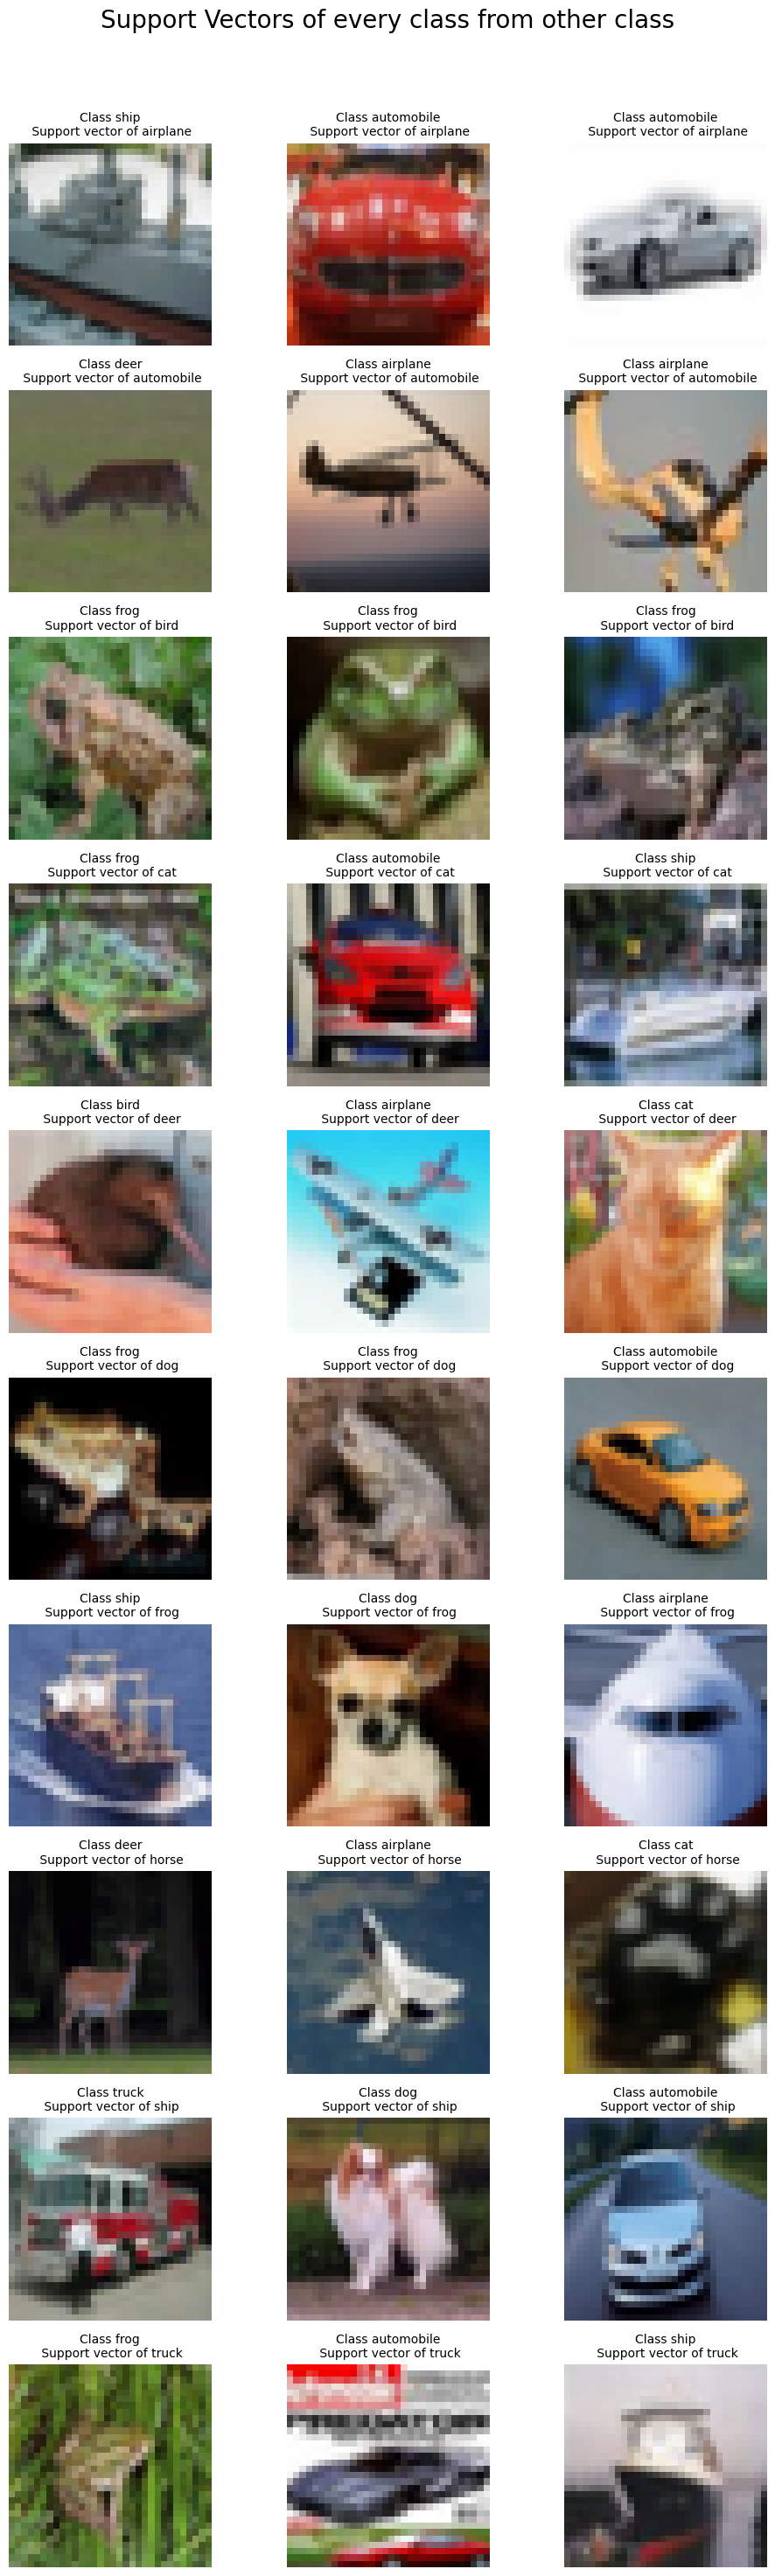

In [283]:
fig, axes = plt.subplots(10, 3, figsize=(10, 30))
fig.suptitle("Support Vectors of every class from other class", fontsize=20)


for class_label in range(len(classes)):
    # Get support vectors corresponding to the current class
    class_support_vectors = images_train[supports[class_label]]
    label = labels_train[supports[class_label]]

    temp = list(zip(class_support_vectors, label))
    np.random.shuffle(temp)
    class_support_vectors, label = zip(*temp)
    class_support_vectors, label = list(class_support_vectors)[0:500], list(label)[0:500]
    
    k = i = 0
    while k < min(3, len(class_support_vectors)):
        # Reshape each support vector to the image shape
        image = class_support_vectors[i].reshape(3,32,32).permute(1,2,0)
        image = image.numpy()*std+mean
        if label[i] != class_label:
            axes[class_label][k].imshow(image.clip(0,1))
            axes[class_label][k].axis('off')  # Hide axes for better visualization
            axes[class_label][k].set_title(f"Class {classes[label[i]]}\n Support vector of {classes[class_label]}", fontsize=10)
            k+=1
        i+=1
        
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Correct and Incorrect Predictions ###

In [53]:
img = images_train[0].reshape(3,32,32).permute(1,2,0)
img = img.numpy()*std+mean

In [ ]:
correct_preds_by_class = {i: [] for i in range(10)}
incorrect_preds_by_class = {i: [] for i in range(10)}

for images, labels in test_loader:
        temp = list(zip(images, labels))
        np.random.shuffle(temp)
        images, labels = zip(*temp)
        images, labels = list(images)[0:500], list(labels)[0:500]
        # print(len(images))
        predicted = SVC.predict(images) #template
        
        for i in range(len(labels)):
            true_label = labels[i].item()
            pred_label = predicted[i].item()
            
            if pred_label == true_label and len(correct_preds_by_class[true_label]) < 10:
                correct_preds_by_class[true_label].append((images[i].numpy(), true_label, pred_label))
            elif pred_label != true_label and len(incorrect_preds_by_class[true_label]) < 10:
                incorrect_preds_by_class[true_label].append((images[i].numpy(), true_label, pred_label))

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x0000022AA78EAAF0>
Traceback (most recent call last):
  File "c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\utils\data\dataloader.py", line 1604, in __del__
    self._shutdown_workers()
  File "c:\Users\Tzagkari\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\utils\data\dataloader.py", line 1562, in _shutdown_workers
    if self._persistent_workers or self._workers_status[worker_id]:
AttributeError: '_MultiProcessingDataLoaderIter' object has no attribute '_workers_status'


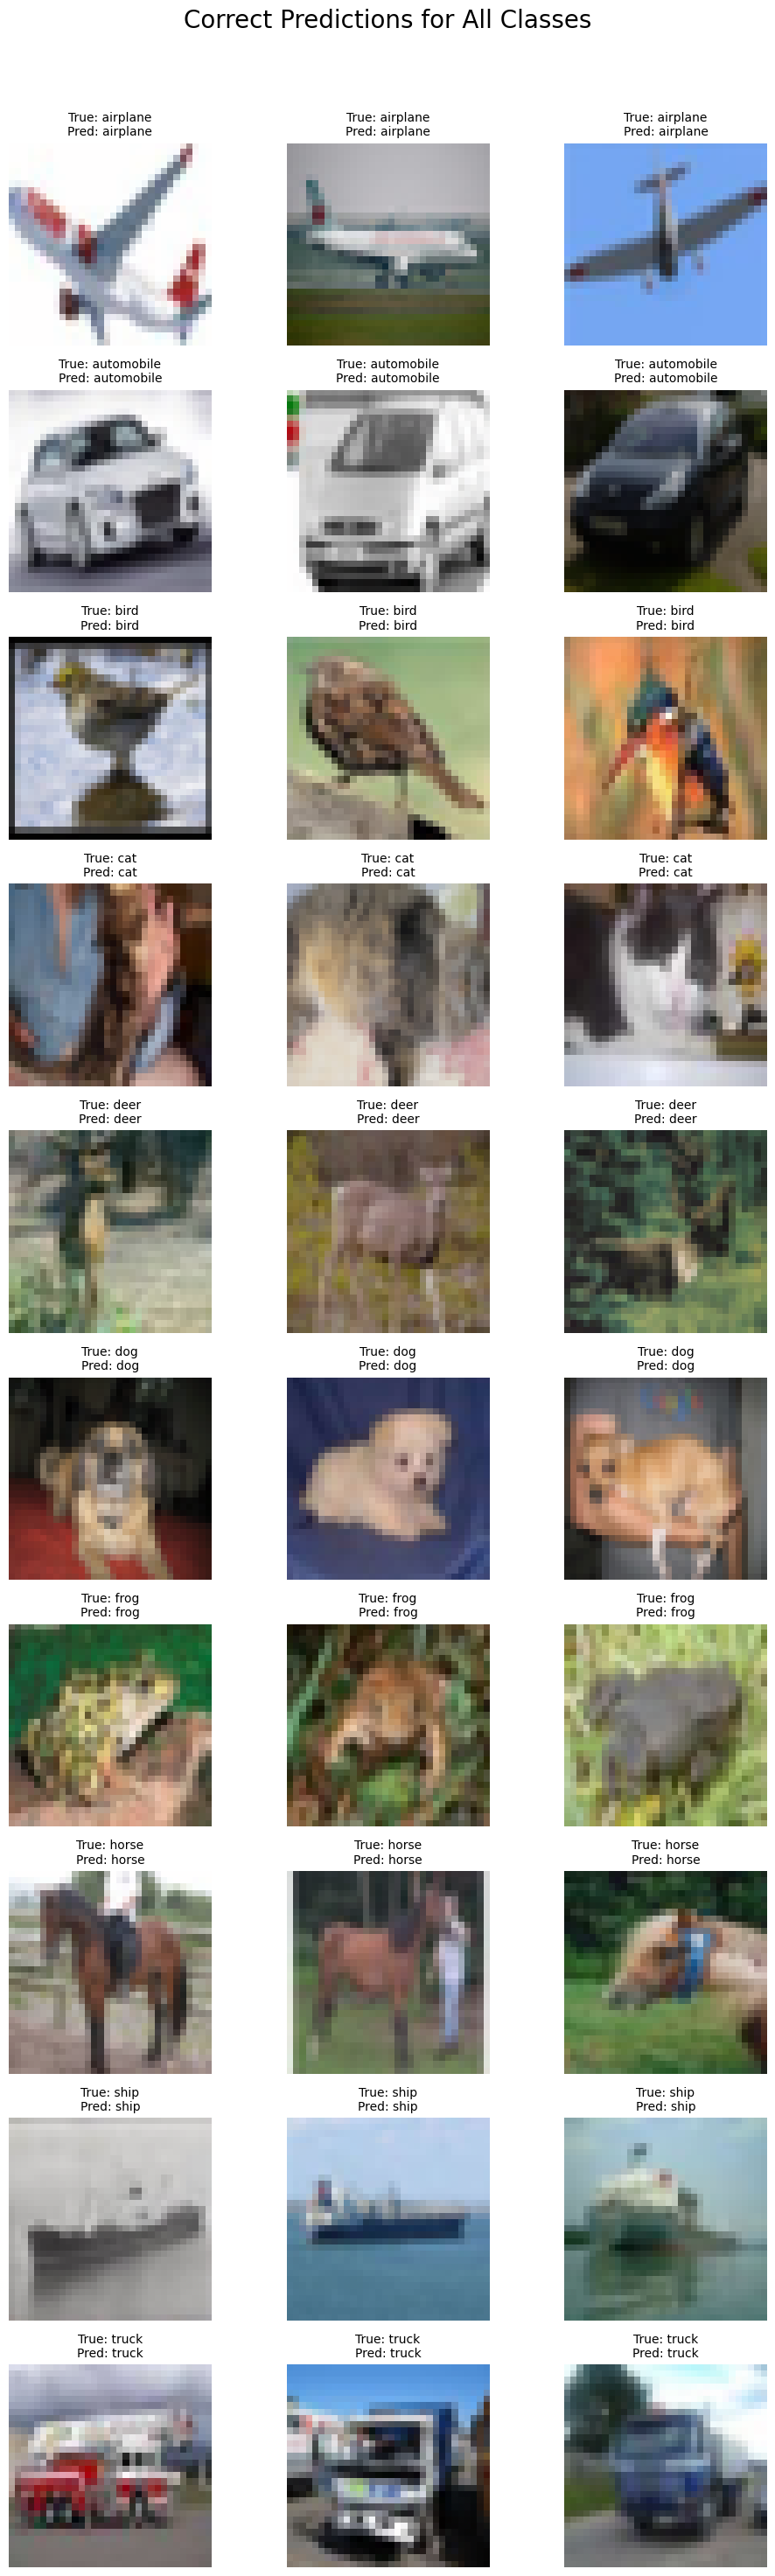

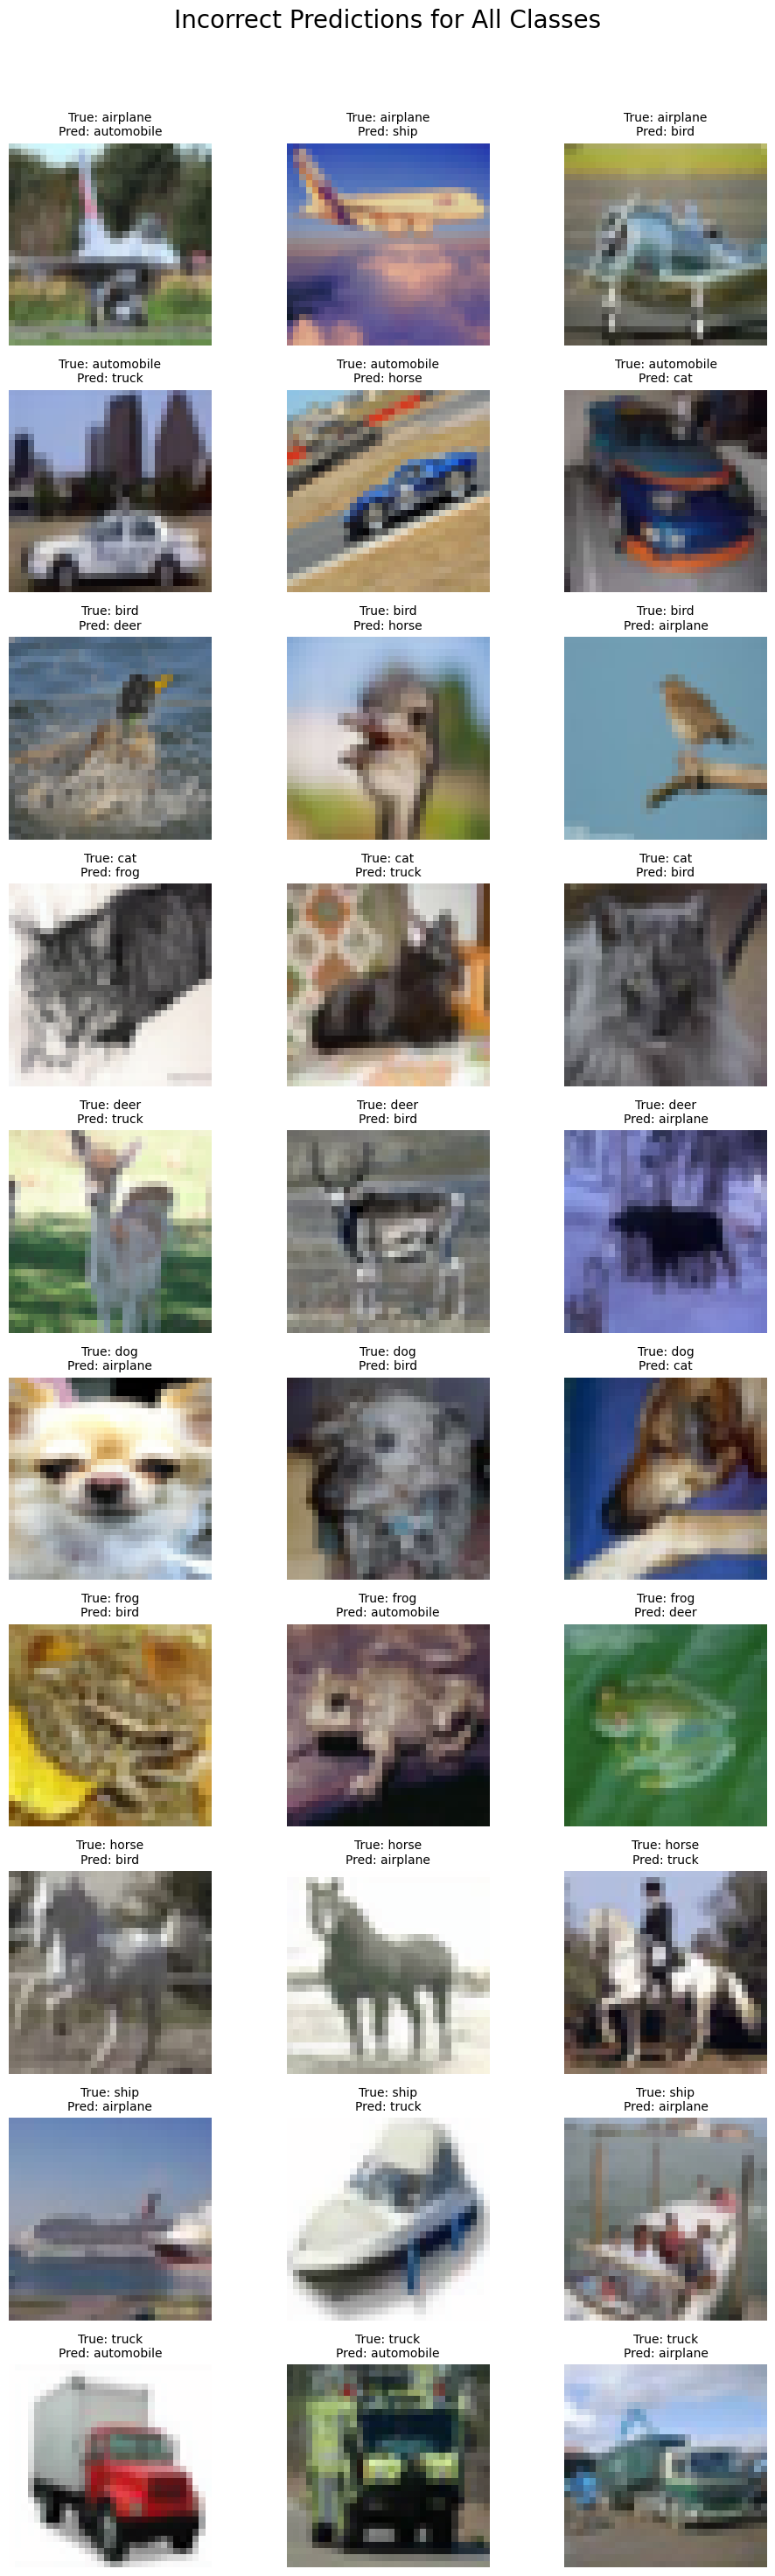

In [210]:
def plot_images_grid(images_dict, title):
    fig, axes = plt.subplots(10, 3, figsize=(10, 10 * 3))
    fig.suptitle(title, fontsize=20)
    for class_idx in range(10):
        images_list = images_dict[class_idx]
        for idx in range(3):
            ax = axes[class_idx, idx]
            ax.axis('off')
            if idx < len(images_list):
                img, true_label, pred_label = images_list[idx]
                img = img.reshape(3,32,32).transpose(1,2,0)
                ax.imshow(((img)*std+mean).clip(0,1))
                ax.set_title(f'True: {classes[true_label]}\nPred: {classes[pred_label]}', fontsize=10)
            else:
                ax.set_visible(False) 

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# print(correct_preds_by_class)/
plot_images_grid(correct_preds_by_class, 'Correct Predictions for All Classes')
plot_images_grid(incorrect_preds_by_class, 'Incorrect Predictions for All Classes')